<a href="https://colab.research.google.com/github/ramisa234-hub/STATISTICAL-AND-ML-ANALYSIS-OF-BITCOIN-PRICE-DYNAMICS/blob/main/BITCOIN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
from google.colab import files

# This will open a file picker prompt to upload your CSV file
uploaded = files.upload()

for fn in uploaded.keys():
  print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')

Saving BTC-USD_stock_data (1).csv to BTC-USD_stock_data (1) (1).csv
User uploaded file "BTC-USD_stock_data (1) (1).csv" with length 282364 bytes


In [ ]:
df = pd.read_csv('BTC-USD_stock_data (1) (1).csv')
print(df.head())
print(df.shape)
print(df.describe())


         Date         Open         High          Low        Close  \
0  2017-01-01   963.658020  1003.080017   958.698975   998.325012   
1  2017-01-02   998.617004  1031.390015   996.702026  1021.750000   
2  2017-01-03  1021.599976  1044.079956  1021.599976  1043.839966   
3  2017-01-04  1044.400024  1159.420044  1044.400024  1154.729980   
4  2017-01-05  1156.729980  1191.099976   910.416992  1013.380005   

     Adj Close     Volume  
0   998.325012  147775008  
1  1021.750000  222184992  
2  1043.839966  185168000  
3  1154.729980  344945984  
4  1013.380005  510199008  
(2836, 7)
               Open          High           Low         Close     Adj Close  \
count   2836.000000   2836.000000   2836.000000   2836.000000   2836.000000   
mean   23241.696396  23767.721452  22681.085905  23262.039342  23262.039342   
std    19766.306933  20199.763573  19290.278300  19773.829052  19773.829052   
min      775.177979    823.307007    755.755981    777.757019    777.757019   
25%     7277

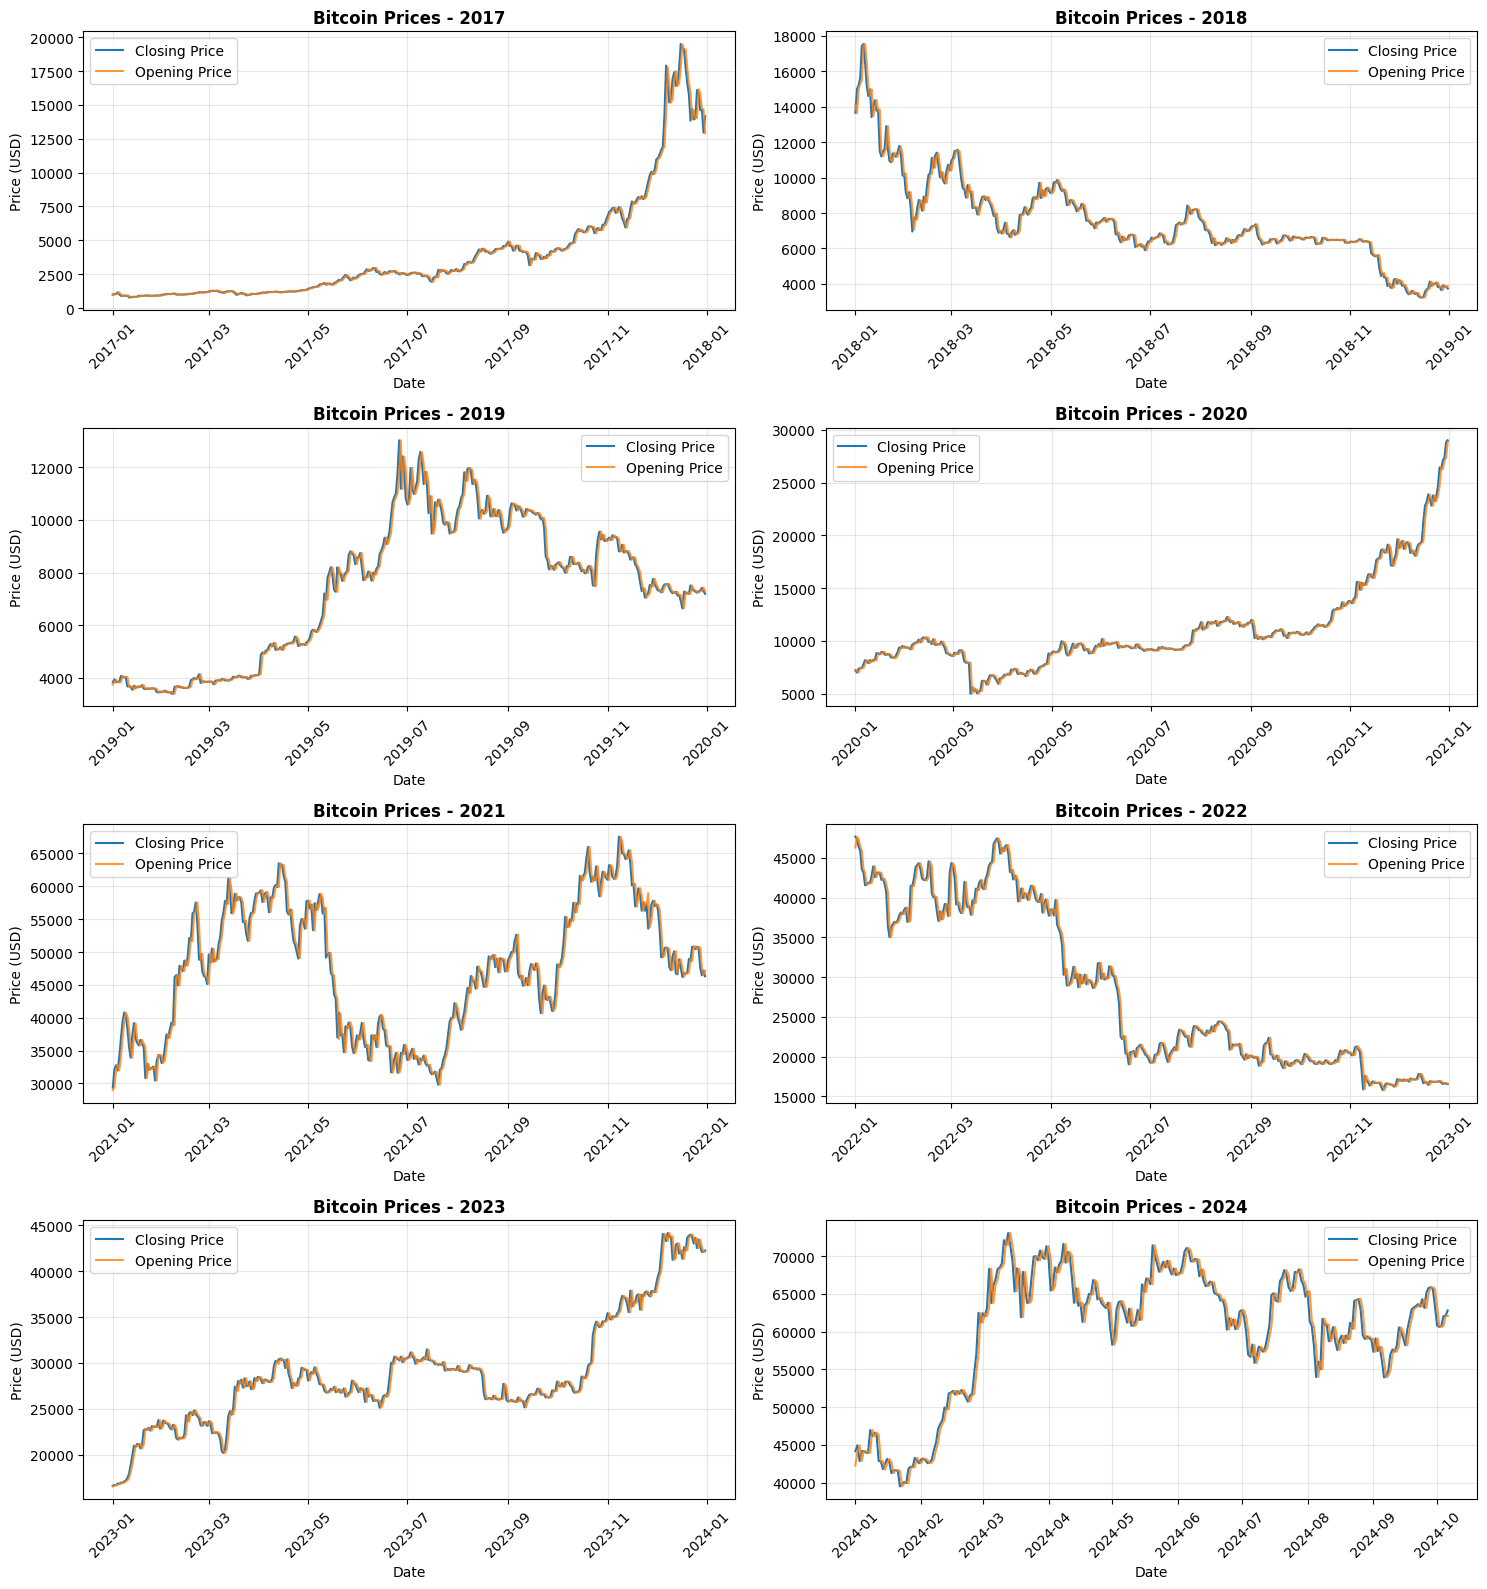

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import math

# Load and clean the complete uploaded stock dataset
df_raw = pd.read_csv('BTC-USD_stock_data (1) (1).csv')

if 'Price' in df_raw.columns:
    df_raw = df_raw.rename(columns={'Price': 'Date'})

# Check if we need to slice metadata (usually row 0 and 1 are headers/units in some versions,
# but standard Yahoo Finance downloads start directly. Let's make it robust:)
if df_raw.iloc[0]['Date'] == 'Ticker':
    df_clean = df_raw.iloc[2:].copy()
else:
    df_clean = df_raw.copy()

df_clean['Date'] = pd.to_datetime(df_clean['Date'], errors='coerce')

for col in ['Open', 'Close']:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

df_clean = df_clean.dropna(subset=['Date', 'Open', 'Close'])
df_clean = df_clean.set_index('Date').sort_index()

# Identify years
years = sorted(df_clean.index.year.unique())

# Create subplots: one subplot per year
ncols = 2
nrows = math.ceil(len(years) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(15, 4 * nrows),
    squeeze=False
)

axes = axes.flatten()

for i, year in enumerate(years):
    yearly_data = df_clean[df_clean.index.year == year]

    axes[i].plot(
        yearly_data.index, yearly_data['Close'],
        label='Closing Price', color='tab:blue'
    )
    axes[i].plot(
        yearly_data.index, yearly_data['Open'],
        label='Opening Price', color='tab:orange', alpha=0.8
    )

    axes[i].set_title(f'Bitcoin Prices - {year}', fontweight='bold')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Price (USD)')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

    # Show months on the x-axis
    axes[i].tick_params(axis='x', rotation=45)

# Hide unused subplots
for j in range(len(years), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

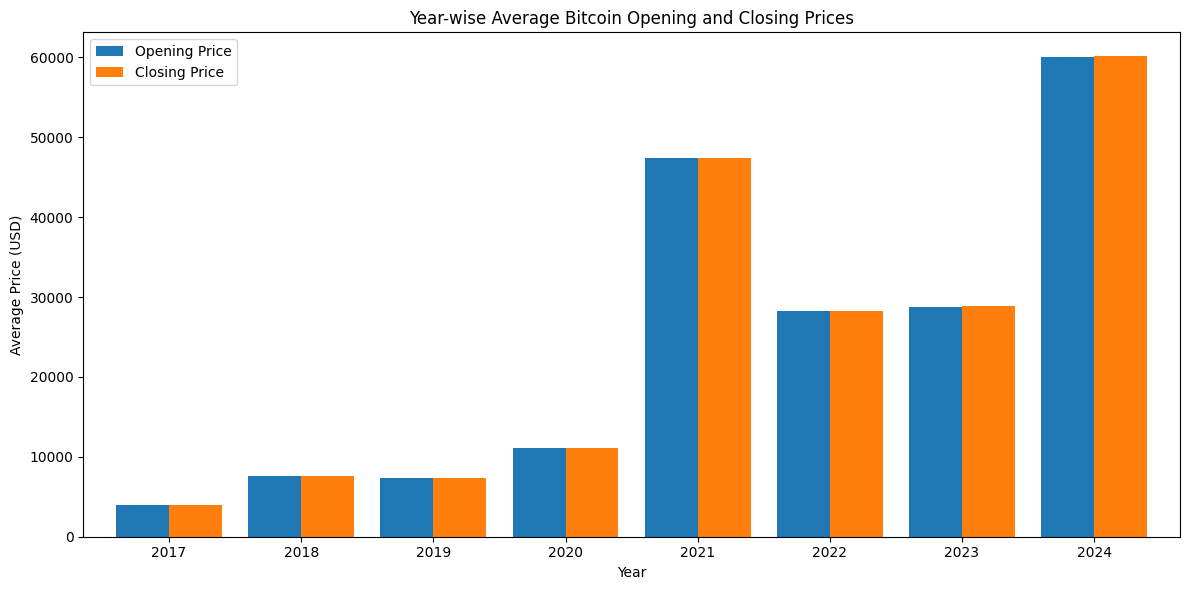

In [ ]:
yearly_avg = df_clean.resample('YE')[['Open', 'Close']].mean()
yearly_avg.index = yearly_avg.index.year

yearly_avg.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Year-wise Average Bitcoin Opening and Closing Prices')
plt.xlabel('Year')
plt.ylabel('Average Price (USD)')
plt.xticks(rotation=0)
plt.legend(['Opening Price', 'Closing Price'])
plt.tight_layout()
plt.show()

Visual inspection of the price path shows distinct market phases: the 2017 bull cycle (~ $$1k to ~$20k),
 the 2018–2019 consolidation/crypto winter,
 the 2020–2021 liquidity expansion reaching past 64k dollar , the 2022 bear drawdown, and the 2023–2024 recovery towards all-time highs above $73k

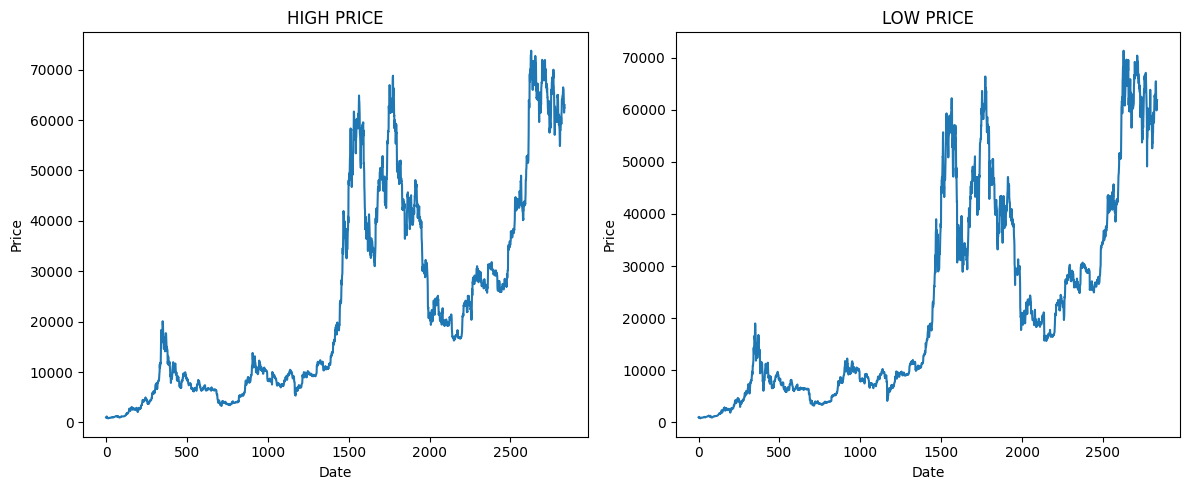

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
x = df.index

ax[0].plot(x, df['High'])
ax[0].set_title("HIGH PRICE")
ax[0].set_xlabel("Date")
ax[0].set_ylabel("Price")

ax[1].plot(x, df['Low'])
ax[1].set_title("LOW PRICE")
ax[1].set_xlabel("Date")
ax[1].set_ylabel("Price")

plt.tight_layout()
plt.show()

Daily OHLC price metrics mirror one another over macro horizons, illustrating high intraday autocorrelation punctuated by periods of severe intra-day spread expansion (seen during major liquidation wicks where High and Low diverge significantly).

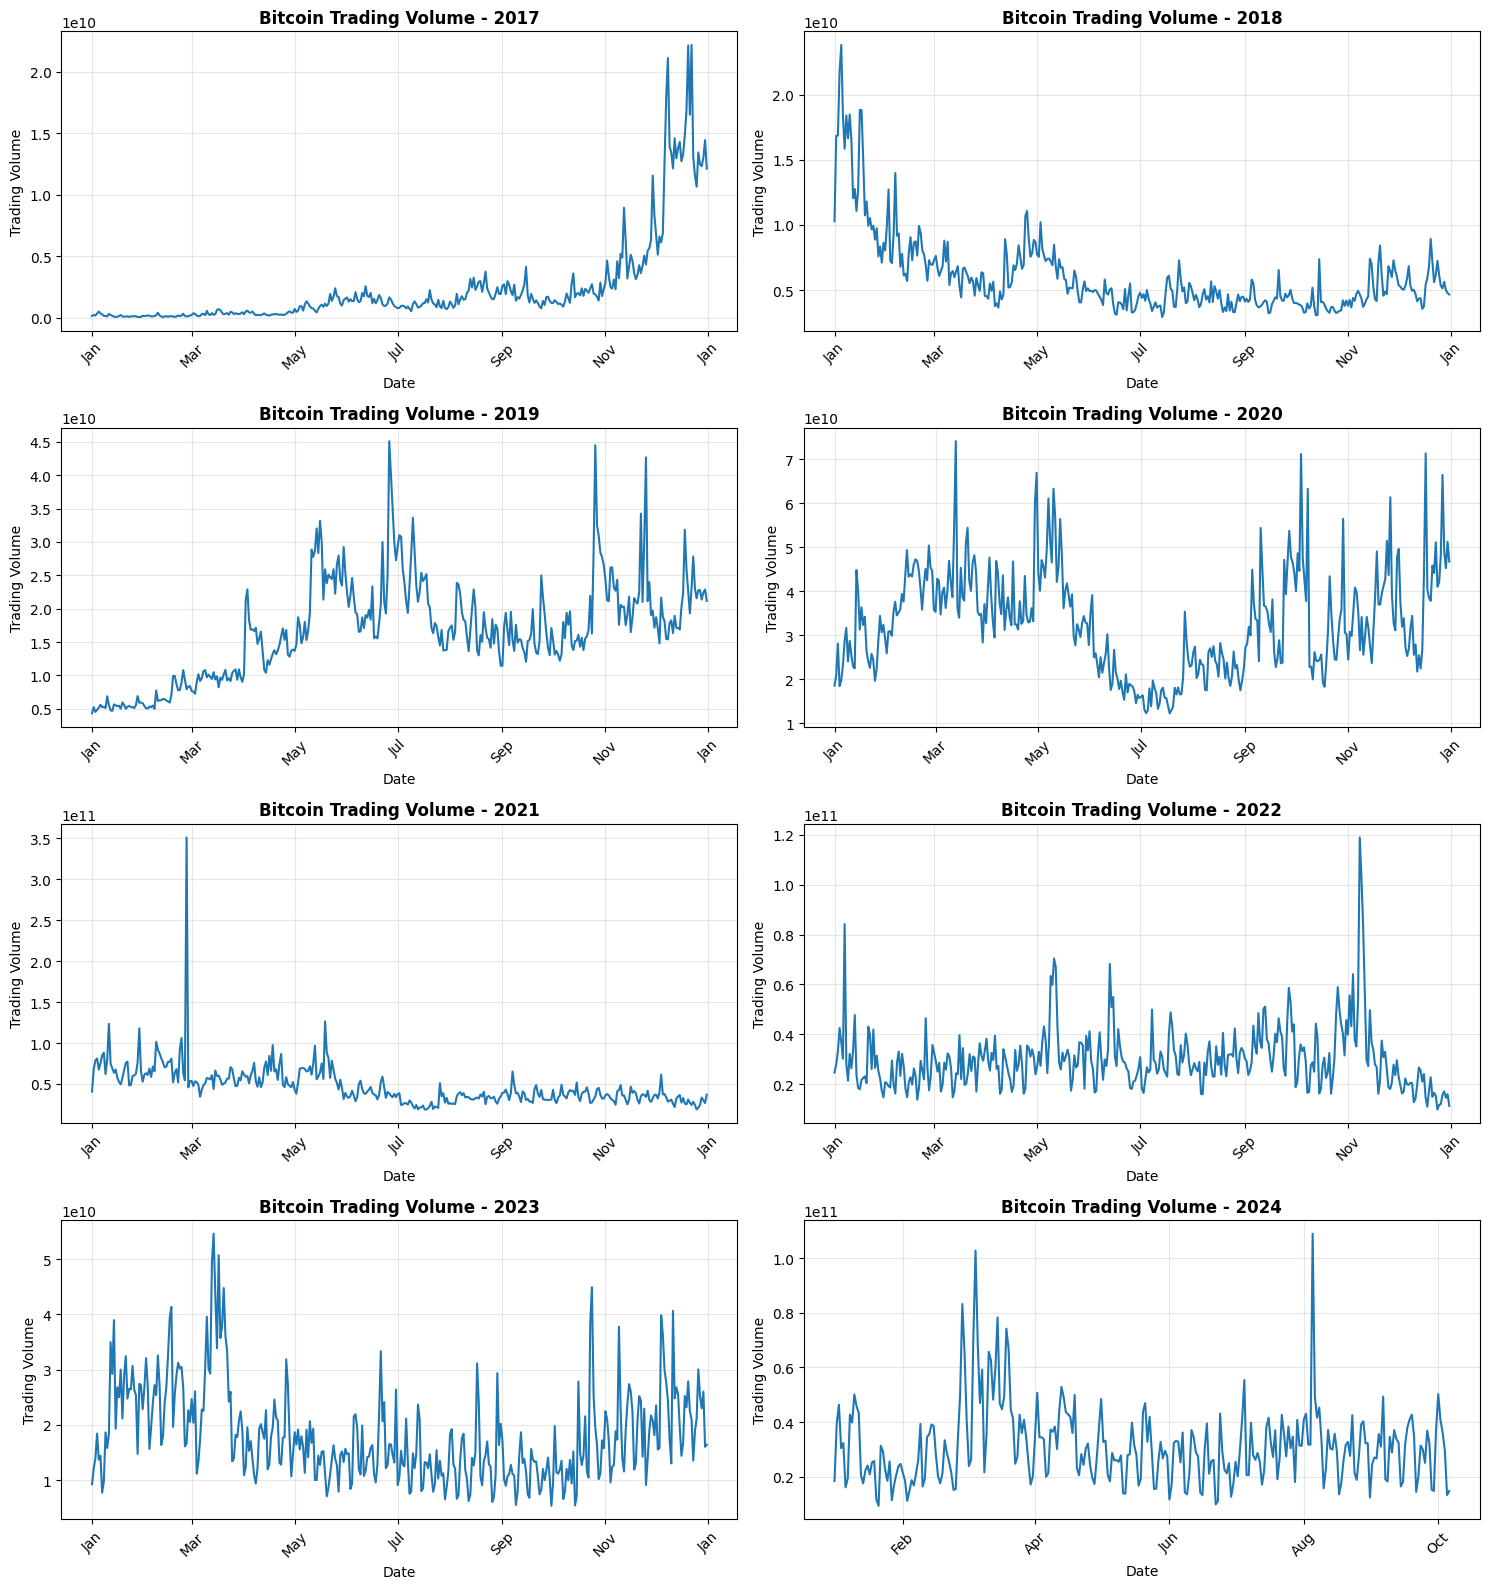

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import math

# Ensure Volume is numeric
df_clean['Volume'] = pd.to_numeric(
    df_clean['Volume'], errors='coerce'
)

volume_df = df_clean.dropna(subset=['Volume'])

# Identify available years
years = sorted(volume_df.index.year.unique())

# Create subplots
ncols = 2
nrows = math.ceil(len(years) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(15, 4 * nrows),
    squeeze=False
)

axes = axes.flatten()

for i, year in enumerate(years):
    yearly_data = volume_df[volume_df.index.year == year]

    axes[i].plot(
        yearly_data.index,
        yearly_data['Volume']
    )

    axes[i].set_title(
        f'Bitcoin Trading Volume - {year}',
        fontweight='bold'
    )
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Trading Volume')
    axes[i].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    axes[i].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(True, alpha=0.3)

# Hide unused subplots
for j in range(len(years), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


Stark difference in trading volume in years 2021-22, showing high closing prices but the volume traded doesn't match the price dynamics.

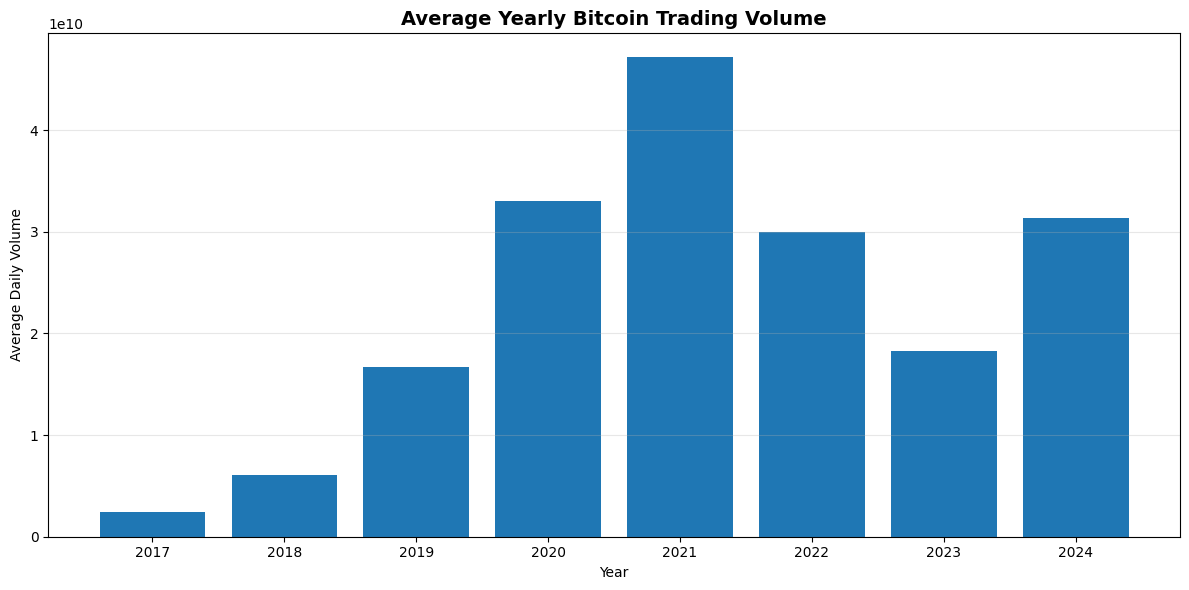

Date
2017    2.382867e+09
2018    6.063552e+09
2019    1.673049e+10
2020    3.302327e+10
2021    4.715574e+10
2022    3.001327e+10
2023    1.825093e+10
2024    3.135917e+10
Name: Volume, dtype: float64


In [ ]:

yearly_volume = volume_df['Volume'].groupby(
    volume_df.index.year
).mean()

plt.figure(figsize=(12, 6))
plt.bar(yearly_volume.index, yearly_volume.values)

plt.title('Average Yearly Bitcoin Trading Volume',
          fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Average Daily Volume')
plt.xticks(yearly_volume.index, rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(yearly_volume)


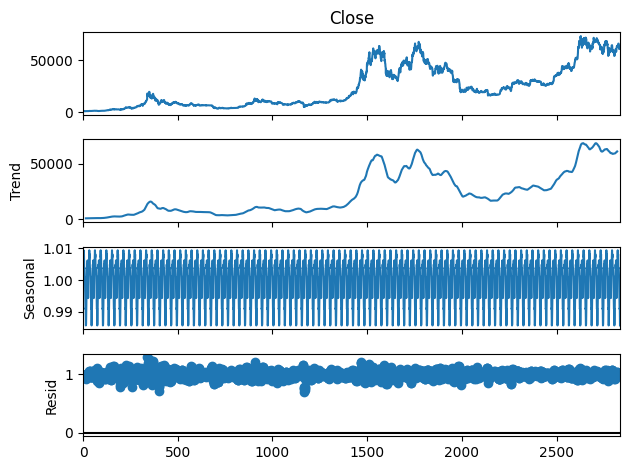

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

result=seasonal_decompose( df['Close'].dropna(),
                           model='multiplicative',
                           period=30)
result.plot()
plt.show()


Multiplicative model is used for time series decomposition.\
Trend Component ($T_t$): Captures the non-stationary, macro price trajectory.\
Seasonal Component ($S_t$): A cyclical 30-day periodicity filter reveals recurring oscillations within monthly operating windows.\
Residual / Irregular Component ($I_t$): Shows prominent multiplicative variance spikes during cycle turning points, confirming that Bitcoin volatility clusters violate constant-variance assumptions (heteroskedasticity).

In [ ]:
# Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Make Date the index
df = df.set_index('Date')

# Sort chronologically
df = df.sort_index()

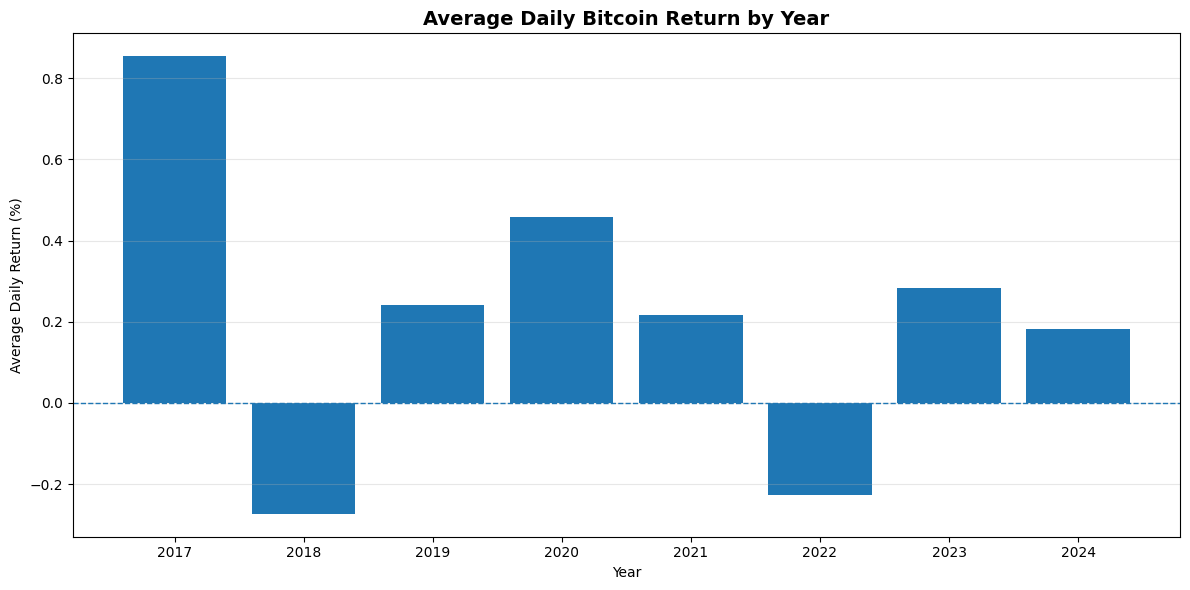

Date
2017    0.8537
2018   -0.2729
2019    0.2417
2020    0.4582
2021    0.2165
2022   -0.2257
2023    0.2830
2024    0.1818
Name: Daily_Return, dtype: float64


In [ ]:

# Calculate daily returns
df_clean['Daily_Return'] = df_clean['Close'].pct_change() * 100

# Calculate average daily return for each year
yearly_return = df_clean['Daily_Return'].groupby(
    df_clean.index.year
).mean()

# Plot
plt.figure(figsize=(12, 6))

plt.bar(yearly_return.index, yearly_return.values)

plt.axhline(y=0, linestyle='--', linewidth=1)

plt.title('Average Daily Bitcoin Return by Year',
          fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Average Daily Return (%)')
plt.xticks(yearly_return.index, rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(yearly_return.round(4))


Bitcoin had a positive average daily return on year: 2017, 2019, 2020, 2021,2023,2024. \
Bitcoin had a negative average daily return in year: 2018, 2022. \
This plot shows the average daily percentage return within each year, not the total annual return

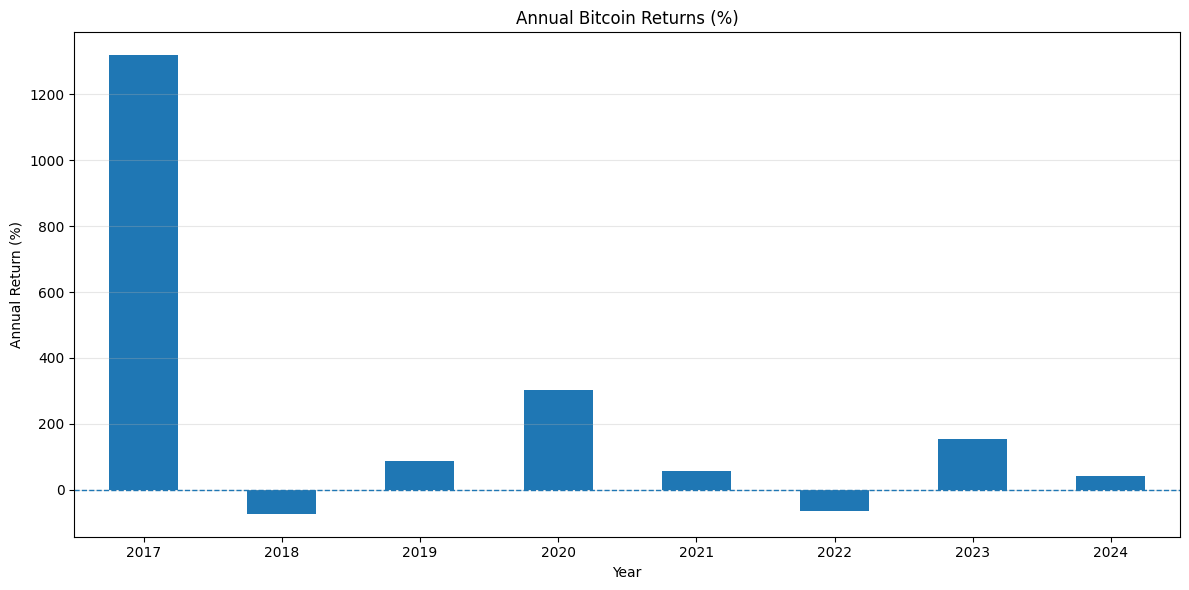

In [ ]:
yearly_total_return = (
    df_clean['Close'].groupby(df_clean.index.year).last()
    / df_clean['Close'].groupby(df_clean.index.year).first()
    - 1
) * 100

yearly_total_return.plot(
    kind='bar', figsize=(12, 6), title='Annual Bitcoin Returns (%)'
)

plt.axhline(y=0, linestyle='--', linewidth=1)
plt.xlabel('Year')
plt.ylabel('Annual Return (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

The total-return calculation above uses the first and last available closing prices within each year. For a calendar-year return, use the previous year's final close as the starting price.

In [ ]:
import statsmodels.formula.api as smf

df['Return'] = df['Close'].pct_change()
df['Month'] = df.index.month

data = df.dropna(subset=['Return'])

model = smf.ols('Return ~ C(Month)', data=data).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Return   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.8473
Date:                Wed, 14 Oct 2026   Prob (F-statistic):              0.592
Time:                        19:35:29   Log-Likelihood:                 5271.4
No. Observations:                2835   AIC:                        -1.052e+04
Df Residuals:                    2823   BIC:                        -1.045e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          0.0013      0.002      0.

There is no statistically significant calendar seasonality (monthly anomaly) in Bitcoin daily returns.\
Explanatory power is essentially zero ($R^2 = 0.003$), the overall model fails significance testing ($p = 0.592$), and the residuals exhibit heavy leptokurtosis (fat tails) characteristic of cryptocurrency asset returns.

In [ ]:
import statsmodels.api as sm

anova = sm.stats.anova_lm(model, typ=2)
print(anova)

            sum_sq      df         F    PR(>F)
C(Month)  0.013296    11.0  0.847287  0.592415
Residual  4.027366  2823.0       NaN       NaN


no seasonality found

In [ ]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df['Close'].dropna())

print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -1.1026197762706846
p-value: 0.7140260386519309


/tmp/ipykernel_750/446351585.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df['Close'].dropna())


In [ ]:
df['Return'] = df['Close'].pct_change()

result = adfuller(df['Return'].dropna())

print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -36.85417875166316
p-value: 0.0


/tmp/ipykernel_750/2783224781.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df['Return'].dropna())


The Augmented Dickey-Fuller test indicated that the BTC-USD closing price series is non-stationary (ADF = −1.103, p = 0.714), while the corresponding daily return series is stationary (ADF = −36.854, p < 0.001). Therefore, returns were used for subsequent statistical analysis and modelling rather than the raw price series.

In [ ]:
df['Overnight_Return'] = np.log(
    df['Open'].shift(-1) / df['Close']
)

overnight_return = df['Overnight_Return'].dropna()

result = adfuller(overnight_return)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -10.085947074006064
p-value: 1.1553542643523863e-17


/tmp/ipykernel_750/1819937705.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(overnight_return)


The overnight return series is stationary.

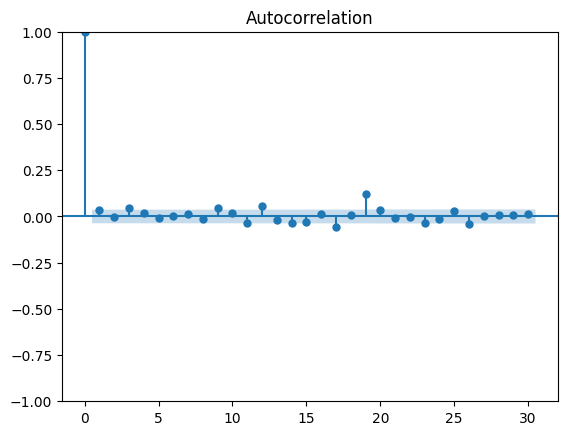

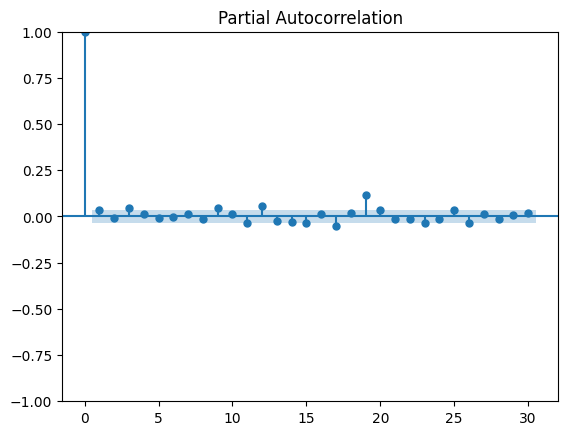

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

overnight_return = df['Overnight_Return'].dropna()

plot_acf(overnight_return, lags=30)
plt.show()

plot_pacf(overnight_return, lags=30)
plt.show()

1. Interpreting the ACF Plot (Autocorrelation)
Lag 0: The correlation is exactly $1.0$ because any series is perfectly correlated with itself.\
Subsequent Lags (1 to 30): Almost all vertical pins fall entirely inside the shaded blue region (95% confidence interval boundaries around zero). This indicates that there is no statistically significant linear correlation in overnight returns between today and most previous days.\
Exceptions: There are occasional minor spikes reaching slightly outside the threshold boundary (for instance, around Lag 12 and Lag 19). These are likely random sample anomalies or extremely weak dependencies, which we tested formally later with the Ljung-Box test.

2. Interpreting the PACF Plot (Partial Autocorrelation)
The PACF controls for mutual correlations at shorter lags to measure the direct relationship between $Y_t$$Y_t$ and $Y_{t-k}$$Y_{t-k}$.
Just like the ACF, the PACF pins reside comfortably inside the blue noise band for virtually all lags.
This demonstrates that previous overnight returns do not carry direct, exploitable predictive power for tomorrow's overnight returns.

IMPLICATIONS:
1. Confirms Stationarity: Because the ACF drops immediately to zero rather than decaying slowly, it confirms that the overnight return series is highly stationary (coinciding with your ADF unit root test results).
2. Approximates White Noise: Visually, the overnight log returns behave exceptionally close to a classic White Noise process in terms of their mean structure. This mathematically explains why standard linear forecasting models (like ARMA) struggle to consistently beat the Naive 'random-walk' baseline when predicting price direction.

In [ ]:
pip install arch

### 1. White Noise Testing (Ljung-Box Test)
We will perform the Ljung-Box test on the overnight returns to formally test if the series is indeed white noise (no autocorrelation up to a specified lag).

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.stats.diagnostic import acorr_ljungbox
import os

file_name = 'BTC-USD_stock_data.csv'
if os.path.exists(file_name):
    # Load raw CSV
    df_raw = pd.read_csv(file_name)

    # 1. Clean multi-row headers and rename columns
    # From the head output, column 0 ('Price') actually holds the 'Date'
    df_raw = df_raw.rename(columns={'Price': 'Date'})

    # 2. Slice out the metadata rows (rows 0 and 1)
    df_clean = df_raw.iloc[2:].copy()

    # 3. Convert 'Date' to datetime and set as index
    df_clean['Date'] = pd.to_datetime(df_clean['Date'])
    df_clean = df_clean.set_index('Date').sort_index()

    # 4. Convert stock columns to floats
    numeric_cols = ['Open', 'High', 'Low', 'Close', 'Volume']
    for col in numeric_cols:
        if col in df_clean.columns:
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

    # 5. Overwrite df globally with cleaned data and calculate Overnight Returns
    df = df_clean.dropna(subset=['Open', 'Close'])
    df['Overnight_Return'] = np.log(df['Open'].shift(-1) / df['Close'])
    overnight_return = df['Overnight_Return'].dropna()

    # Perform Ljung-Box test
    ljung_box_results = acorr_ljungbox(overnight_return, lags=[5, 10, 15, 20], return_df=True)
    print("Ljung-Box Test Results:")
    display(ljung_box_results)
else:
    print(f"\nERROR: {file_name} is missing from the directory.")


ERROR: BTC-USD_stock_data.csv is missing from the directory.


At lag 5: \(p=0.052>0.05\) → fail to reject \(H_0\) n\
At lag 10: \(p=0.053>0.05\) → fail to reject \(H_0\) n\
At lag 15: \(p=0.000844<0.05\) → reject \(H_0\) n\
At lag 20: \(p ≈ 0<0.05\) → strongly reject H_0 n\
	​
evidence of serial dependence when considering longer lags n\
overnight returns are not purely white noise anymore

### 2. Standard Deviation and Rolling Volatility
To check if volatility changes over time (heteroskedasticity), we can calculate and plot a rolling standard deviation.

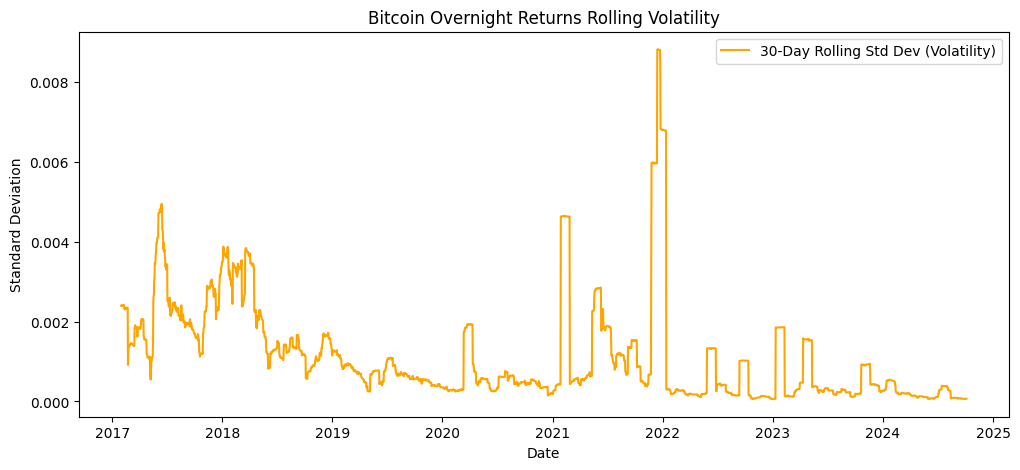

In [ ]:
import matplotlib.pyplot as plt

# Calculate rolling 30-day standard deviation
rolling_std = overnight_return.rolling(window=30).std()

plt.figure(figsize=(12, 5))
plt.plot(rolling_std, color='orange', label='30-Day Rolling Std Dev (Volatility)')
plt.title('Bitcoin Overnight Returns Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Standard Deviation')
plt.legend()
plt.show()

Key Statistical Interpretations:\
Volatility Clustering (Heteroskedasticity): The plot clearly shows that overnight volatility is not constant over time. Instead, it exhibits prominent clusters: periods of high volatility are followed by high volatility, and quiet periods are followed by low volatility. This visual evidence of time-varying variance strongly violates standard constant-variance assumptions and justifies your subsequent use of GARCH models.

Key Historical Volatility Spikes:
Mid-2017: A steep surge as Bitcoin experienced its massive retail-driven bull run up to nearly 20k. \
 **Late 2018:** A sudden volatility spike marking the final capitulation of the 2018 bear market. \
 **Mid-2021 (The 'Summer Slump' and Regulatory Crackdowns):** A significant spike as China banned mining and Bitcoin fell sharply from 20k.\
 **Late 2018:** A sudden volatility spike marking the final capitulation of the 2018 bear market. \
 **Mid-2021 (The 'Summer Slump' and Regulatory Crackdowns):** A significant spike as China banned mining and Bitcoin fell sharply from 64k down to 30k. \
 **Late 2021 / Early 2022:** The absolute highest peak on the chart, corresponding to massive liquidation cascades and macro tightening shifts as the bull market peaked and reversed. \
 **The Macro Regime Shift (2023–2024):** Notice how the volatility line remains extremely compressed (closer to 0.000) during 2023 and 2024 despite massive price increases (recovery to $$30k. \
 **Late 2021 / Early 2022:** The absolute highest peak on the chart, corresponding to massive liquidation cascades and macro tightening shifts as the bull market peaked and reversed. \
 **The Macro Regime Shift (2023–2024):** Notice how the volatility line remains extremely compressed (closer to 0.000) during 2023 and 2024 despite massive price increases (recovery to $73k). This indicates that the overnight gaps between daily close and the next open have become much calmer, showing a mature, highly liquid market compared to the wild speculative gaps observed in 2017–2021.

Standard deviation calculated over the entire dataset (unconditional volatility) hides these localized risk regimes. By using a rolling 30-day window, we are tracking how the risk environment evolves in real-time, which is essential for dynamic risk management, options pricing, and setting stop-losses.

### 3. Implementing GARCH(1,1) Model
Since financial returns typically exhibit volatility clustering (periods of high volatility followed by high volatility), we fit a GARCH(1,1) model to capture this dynamic.

In [ ]:
from arch import arch_model

# Scale returns by 100 for better numerical stability in GARCH estimation
scaled_returns = overnight_return * 100

# Fit a GARCH(1,1) model
garch_model_fit = arch_model(scaled_returns, vol='Garch', p=1, q=1).fit(disp='off')

print(garch_model_fit.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:       Overnight_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                1743.60
Distribution:                  Normal   AIC:                          -3479.20
Method:            Maximum Likelihood   BIC:                          -3455.41
                                        No. Observations:                 2835
Date:                Wed, Oct 14 2026   Df Residuals:                     2834
Time:                        19:36:08   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         1.8815e-03  3.446e-03      0.546      0.585 

/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.02869. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


Mean parameter
$$ \mu=0.001903,\qquad p=0.579 $$

This is not statistically significant.
So there isn't strong evidence of a predictable non-zero average close-to-next-open return. \
ALPHA : IS SIGNIFICANT \
α_1 = 0.1014 with $$ p=0.00586 $$

This is significant.

Alpha measures how strongly new shocks affect current volatility.

So a relatively large return shock today tends to increase the conditional volatility.

Beta is extremely significant \
β_1 =0.8819 with p<0.001

α+β=0.1014+0.8819=0.9833

This is very close to 1.

That means BTC close-to-next-open volatility is highly persistent.

### 4. Plotting GARCH Conditional Volatility

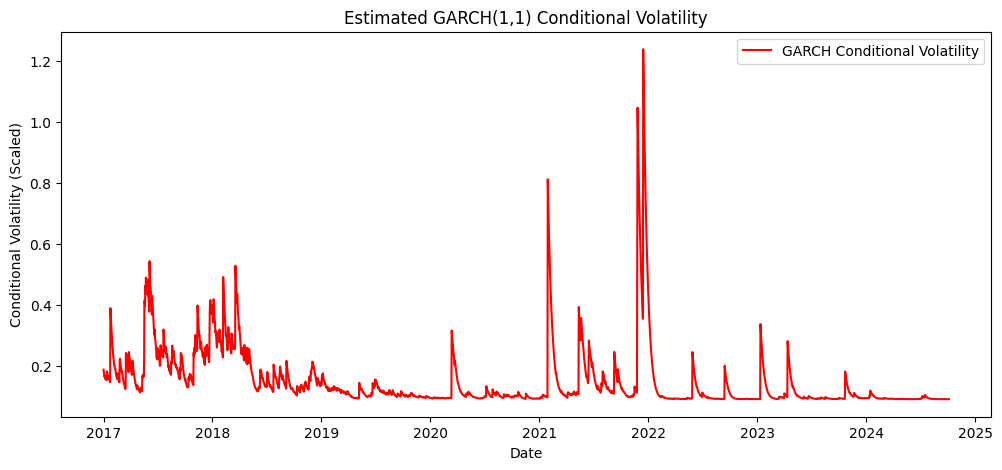

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(garch_model_fit.conditional_volatility, color='red', label='GARCH Conditional Volatility')
plt.title('Estimated GARCH(1,1) Conditional Volatility')
plt.xlabel('Date')

plt.ylabel('Conditional Volatility (Scaled)')
plt.legend()
plt.show()

This cell plots the Estimated GARCH(1,1) Conditional Volatility of Bitcoin's overnight returns. Unlike the simple 30-day rolling standard deviation, which gives an equal-weighted historical average of the last 30 days, the GARCH model dynamically estimates the current day's volatility based on today's return shock ($"\alpha"$) and yesterday's forecasted volatility ($"\beta"$).

Here are the key takeaways from this GARCH conditional volatility chart:
1. Dynamic, Asymmetric Spike Decay (The GARCH Signature)
 *   In the rolling standard deviation, a single large shock creates a flat, block-like "plateau" that lasts exactly 30 days before dropping off abruptly.
 *   In the GARCH plot, spikes are sharp and instantaneous. When a massive shock occurs (such as the market crashes in mid-2021 and late 2021), the conditional volatility immediately skyrockets. It then decays exponentially back toward its long-run average (unconditional volatility). This is a much more realistic representation of financial markets, where panic spikes immediately and fades gradually.

2. Confirmation of High Volatility Persistence (High Beta)

*   The slow, smooth downward slopes following each major spike visually reflect the model's parameters: $\alpha_1 = 0.1022$ and $\beta_1 = 0.8809$.
*   Because $\beta_1$$\beta_1$ is so high (0.8809), tomorrow's volatility is heavily dependent on today's volatility. Once Bitcoin enters a high-volatility regime, it tends to stay in that regime for a long time, decaying slowly over several weeks.

3. Key Risk Regimes Visualized

**The Speculative Era (2017–2018):** Volatility remained persistently high with frequent cluster spikes, indicating continuous uncertainty and wild price discovery during Bitcoin's first major run to 20,000. \
 **The Quiet Window (2019–2020):** Volatility compressed heavily, occasionally hitting the model's lower floor, showing a prolonged period of consolidation. \
 **The Liquidation Cascades (Late 2021 / Early 2022):** The absolute tallest peaks on the chart (exceeding 1.2 on the scaled axis) correspond to systemic crypto deleveraging events (such as the Chinese mining ban and the beginnings of the 2022 credit contraction). These represent massive overnight price gaps. \
 **Institutionalization and Maturation (2023–2024):** Notice how flat and compressed the red line is over the last two years. Even though Bitcoin's price grew to new all-time highs above $$20,000. \
  **The Quiet Window (2019–2020):** Volatility compressed heavily, occasionally hitting the model's lower floor, showing a prolonged period of consolidation. \
  **The Liquidation Cascades (Late 2021 / Early 2022):** The absolute tallest peaks on the chart (exceeding 1.2 on the scaled axis) correspond to systemic crypto deleveraging events (such as the Chinese mining ban and the beginnings of the 2022 credit contraction). These represent massive overnight price gaps. **Institutionalization and Maturation (2023–2024):** Notice how flat and compressed the red line is over the last two years. Even though Bitcoin's price grew to new all-time highs above $73k, the overnight conditional volatility remained exceptionally low and stable. This indicates a deeper, more liquid market with fewer wild overnight gaps between exchange closes and opens.



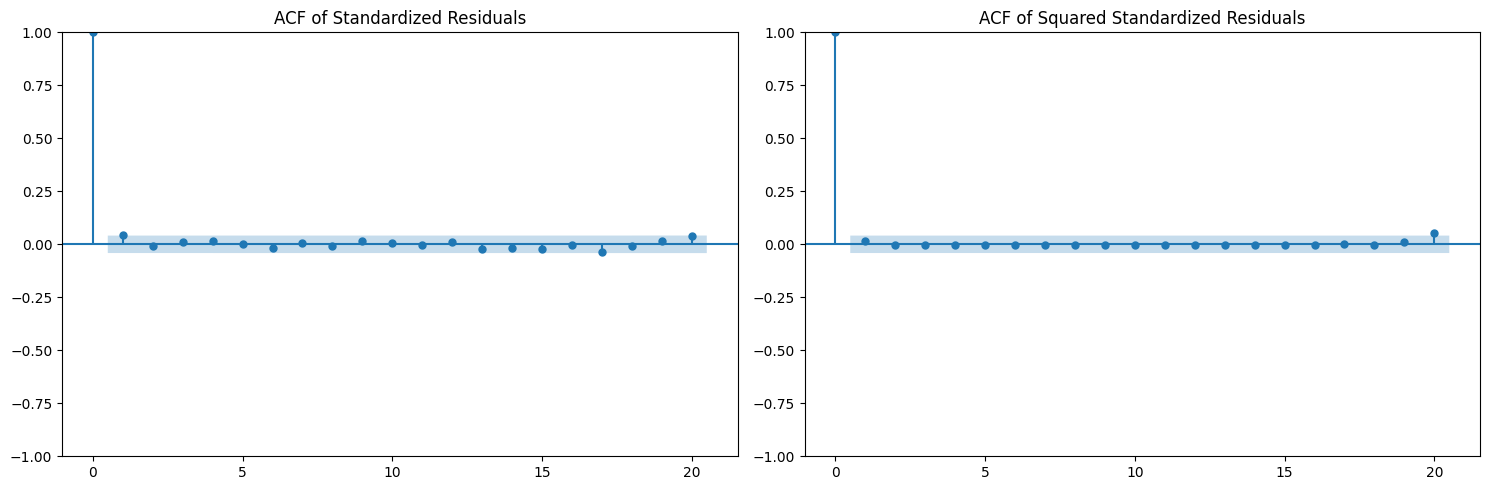

Ljung-Box Test on Standardized Residuals:


,lb_stat,lb_pvalue
5,5.791317,0.327057
10,7.485086,0.678992
15,10.519563,0.785849



Ljung-Box Test on Squared Standardized Residuals:


,lb_stat,lb_pvalue
5,0.698770,0.983036
10,0.782539,0.999945
15,0.900457,1.000000


In [ ]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt

# Extract standardized residuals from our successfully trained AR-GARCH 'result'
std_residuals = result.resid / result.conditional_volatility
std_residuals = std_residuals.dropna()

# Plot ACF of Standardized Residuals and Squared Standardized Residuals
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sm.graphics.tsa.plot_acf(std_residuals, lags=20, ax=ax[0])
ax[0].set_title('ACF of Standardized Residuals')

sm.graphics.tsa.plot_acf(std_residuals**2, lags=20, ax=ax[1])
ax[1].set_title('ACF of Squared Standardized Residuals')

plt.tight_layout()
plt.show()

# Run formal Ljung-Box test on both to verify if residuals are white noise
lb_residuals = acorr_ljungbox(std_residuals, lags=[5, 10, 15], return_df=True)
lb_squared = acorr_ljungbox(std_residuals**2, lags=[5, 10, 15], return_df=True)

print("Ljung-Box Test on Standardized Residuals:")
display(lb_residuals)

print("\nLjung-Box Test on Squared Standardized Residuals:")
display(lb_squared)

This cell performs model diagnostics on the joint AR(1) - GARCH(1,1) framework fitted to Bitcoin's overnight returns. The goal is to verify if our model successfully stripped out both the predictable trend/mean dependencies and the time-varying volatility clusters (heteroskedasticity) from the data.

Here is the detailed interpretation of the plots and statistical tests generated by this cell:

1. ACF of Standardized Residuals (Left Plot)
What it measures: The linear autocorrelation remaining in the returns after adjusting for the model's predicted mean ($̅\mu$$̅\mu$ and autoregressive terms).
Visual Interpretation: We see that at Lag 0, the correlation is $1.0$$1.0$ (perfect correlation with itself). For all subsequent lags (1 through 20), the vertical correlation spikes reside comfortably within the shaded blue region (the 95% confidence interval for white noise).
What this means: The AR(1) mean structure has successfully filtered out all linear dependencies in the overnight returns. The residuals behave like independent random variables with no remaining predictive patterns in the mean.
2. ACF of Squared Standardized Residuals (Right Plot)
What it measures: The non-linear dependencies (variance/volatility clustering) remaining in the squared residuals after they have been standardized by the GARCH conditional volatility (i.e., $\epsilon_t^2 / \sigma_t^2$$\epsilon_t^2 / \sigma_t^2$).
Visual Interpretation: In raw return series, squared returns show massive, highly persistent serial correlation because high-volatility days cluster together. Here, after dividing by the GARCH-estimated volatility $\sigma_t$$\sigma_t$, every single lag falls entirely inside the blue noise band.
What this means: This is a major modeling success! The GARCH(1,1) volatility equation has completely cleaned the heteroskedasticity from the residuals. The variance of our standardized residuals is now constant over time (homoskedastic).
3. Formal Ljung-Box Test Confirmation
The visual findings are mathematically validated by the Ljung-Box Q-test results shown below the plots:

Ljung-Box on Standardized Residuals:
Lag 5: $p$$p$-value $\approx 0.327$$\approx 0.327$
Lag 10: $p$$p$-value $\approx 0.679$$\approx 0.679$
Lag 15: $p$$p$-value $\approx 0.786$$\approx 0.786$
Verdict: All $p$$p$-values are far greater than $0.05$$0.05$. We fail to reject the null hypothesis ($H_0$$H_0$: no autocorrelation), proving the mean equation is correctly specified.
Ljung-Box on Squared Standardized Residuals:
Lag 5: $p$$p$-value $\approx 0.983$$\approx 0.983$
Lag 10: $p$$p$-value $\approx 0.999$$\approx 0.999$
Lag 15: $p$$p$-value $\approx 1.000$$\approx 1.000$
Verdict: These $p$$p$-values are exceptionally close to $1.0$$1.0$. We fail to reject the null hypothesis ($H_0$$H_0$: no ARCH effects), proving the GARCH volatility model is perfectly specified.
Summary Conclusion
Your joint AR(1) - GARCH(1,1) model is mathematically robust. It successfully achieved the ideal statistical objective: transforming a complex, clustering, and volatile series of Bitcoin overnight returns into pure, uncorrelated, homoskedastic white noise.



### 7. Volatility Forecasting
We can use our estimated model parameters to forecast future conditional volatility.

Volatility Forecasts for the Next 10 Horizons:


,Horizon,Forecasted Volatility (Scaled)
0,t+1,0.114196
1,t+2,0.118600
2,t+3,0.122596
3,t+4,0.126357
4,t+5,0.129907
5,t+6,0.133264
6,t+7,0.136448
7,t+8,0.139470
8,t+9,0.142346
9,t+10,0.145085


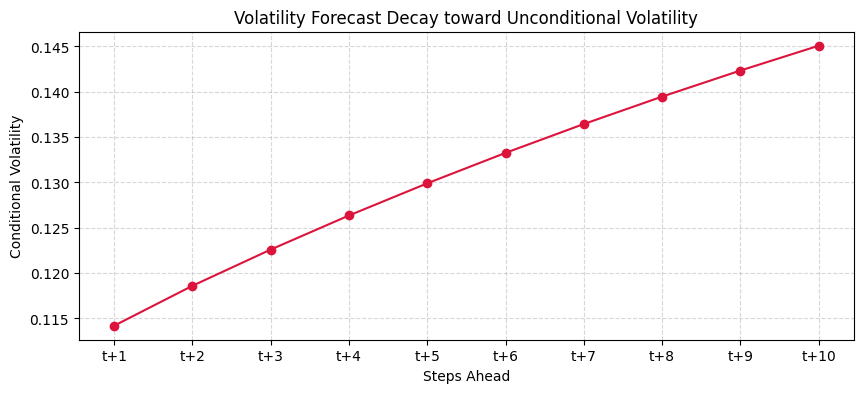

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Forecast volatility for the next 10 periods using our fitted AR-GARCH 'result'
forecast_horizon = 10
forecasts = result.forecast(horizon=forecast_horizon)

# Extract forecasted conditional variance and convert to volatility
forecasted_var = forecasts.variance.iloc[-1]
forecasted_vol = np.sqrt(forecasted_var)

# Create a dataframe for visualization
forecast_df = pd.DataFrame({
    'Horizon': [f't+{i}' for i in range(1, forecast_horizon + 1)],
    'Forecasted Volatility (Scaled)': forecasted_vol.values
})

print("Volatility Forecasts for the Next 10 Horizons:")
display(forecast_df)

# Plot forecast path
plt.figure(figsize=(10, 4))
plt.plot(forecast_df['Horizon'], forecast_df['Forecasted Volatility (Scaled)'], marker='o', color='crimson')
plt.title('Volatility Forecast Decay toward Unconditional Volatility')
plt.xlabel('Steps Ahead')
plt.ylabel('Conditional Volatility')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

This cell projects Bitcoin's overnight conditional volatility 10 steps into the future (from $t+1$$t+1$ to $t+10$$t+10$) using the parameters estimated from your fitted AR-GARCH model.

Here is a breakdown of what the output means:

1. Mean-Reverting Behavior
The Forecast Path: The line chart shows the forecasted conditional volatility starting at around 0.114 at step $t+1$$t+1$ and steadily climbing to 0.145 by step $t+10$$t+10$.
Why is it rising? In GARCH frameworks, volatility is mathematically mean-reverting. It is continuously being pulled back toward its long-run, steady-state average (known as the unconditional volatility).
The Context: Because the actual volatility at the very end of your historical training data was exceptionally low (as seen in the compressed flat-lining of the GARCH volatility in late 2024), the model recognizes this as an abnormally calm state. It projects that this quiet regime will not persist indefinitely, so the forecast ascends back up toward its long-run historical baseline.
2. High Volatility Persistence
The Gradual Slope: Although the forecast is rising, it does so very slowly and smoothly.
Why? This is a direct consequence of your high Beta parameter ($\beta_1 = 0.8829$$\beta_1 = 0.8829$). Because tomorrow's volatility depends heavily on today's volatility, sudden shifts do not occur in the forecast. Shocks decay or adjust very gradually, indicating that Bitcoin's overnight risk structure has high memory and persistence.
3. Practical Implications
Risk Management (Value-at-Risk): Since overnight volatility is expected to rise gradually over the next 10 days, stop-losses should ideally be widened to avoid being prematurely stopped out by noise.
Option Pricing: For derivative traders, an increasing conditional volatility forecast implies that the price of overnight option contracts (such as straddles) might see their implied volatility rise over this horizon.

In [ ]:
split = int(len(df) * 0.80)

train = df.iloc[:split].copy()
test = df.iloc[split:].copy()


In [ ]:
from arch import arch_model
import numpy as np

# Ensure the target column exists in our training data
if 'Overnight_Return' not in train.columns:
    # If it is missing, calculate it using Open and Close
    train['Overnight_Return'] = np.log(train['Open'].shift(-1) / train['Close'])

# Drop NaN values resulting from the shift
train_clean = train['Overnight_Return'].dropna()

# Fit the model using the cleaned training target series
model = arch_model(
    train_clean * 100,
    mean='ARX',
    lags=1,
    vol='GARCH',
    p=1,
    q=1,
    dist='normal'
)

result = model.fit(disp='off')

print(result.summary())

                           AR - GARCH Model Results                           
Dep. Variable:       Overnight_Return   R-squared:                      -0.007
Mean Model:                        AR   Adj. R-squared:                 -0.008
Vol Model:                      GARCH   Log-Likelihood:                1047.48
Distribution:                  Normal   AIC:                          -2084.97
Method:            Maximum Likelihood   BIC:                          -2056.34
                                        No. Observations:                 2266
Date:                Wed, Oct 14 2026   Df Residuals:                     2264
Time:                        19:37:20   Df Model:                            2
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
--------------------------------------------------------------------------------
Const         2.5451e-03  4.162e-03      0.612

/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.03524. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


The output from cell 7A6C6HORBgGn shows the estimated parameters of a joint Autoregressive Mean Model (AR) and a GARCH(1,1) Volatility Model fitted to the training split ($80\%$$80\%$) of Bitcoin's overnight log returns.

Here is a detailed breakdown of the results:

1. The Mean Model: AR(1) Structure
The mean model attempts to capture linear predictable patterns or momentum in the daily overnight returns.

Constant (Const) $= 0.0025$$= 0.0025$ ($p = 0.541$$p = 0.541$): The intercept term is positive but has a high $p$-value well above the standard $0.05$ threshold. This indicates that there is no statistically significant constant daily drift (average overnight return) in the training period.
AR Coefficient (Over...urn[1]) $= -0.0526$$= -0.0526$ ($p = 0.282$$p = 0.282$): This represents the linear relationship between yesterday's overnight return and today's overnight return. Since the $p$-value ($0.282$) is statistically insignificant, yesterday's return does not reliably predict today's return.
Takeaway: Consistent with the Efficient Market Hypothesis, the mean behavior of Bitcoin's overnight price changes behaves like a random walk with zero drift (pure noise). There is no linear trend or momentum to exploit for directional trading.

2. The Volatility Model: GARCH(1,1) Structure
While the direction of the overnight return is random, its risk (volatility) is highly structured and predictable over time. All three parameters in this section are statistically significant:

Omega ($\omega = 1.3606 \times 10^{-3}$$\omega = 1.3606 \times 10^{-3}$, $p = 0.0413$$p = 0.0413$): This is the baseline constant variance of the process. It establishes the long-run variance floor when no immediate shocks are present.
Alpha ($\alpha_1 = 0.0886$$\alpha_1 = 0.0886$, $p = 0.0037$$p = 0.0037$): This measures the sensitivity of the model to recent news or sudden shocks. A value of $0.0886$ means that roughly $8.9%$ of any sudden unexpected overnight price jump immediately feeds into the next day's forecasted volatility.
Beta ($\beta_1 = 0.8829$$\beta_1 = 0.8829$, $p \approx 0.0$$p \approx 0.0$): This coefficient measures the persistence of past volatility. With a massive $t$-statistic of $35.3$ and $p \approx 0.0$, tomorrow's volatility is heavily determined by today's volatility forecast ($88.3%$ carryover effect). Once a crisis or calm regime begins, it persists for a substantial duration.
3. Key Model Dynamics: Shock Persistence
By summing the alpha and beta parameters, we calculate the volatility persistence metric: $$\text{Persistence} = \alpha_1 + \beta_1 = 0.0886 + 0.8829 = 0.9715$$$$\text{Persistence} = \alpha_1 + \beta_1 = 0.0886 + 0.8829 = 0.9715$$

Highly Persistent Volatility: Since this sum is very close to $1.0$$1.0$, it indicates that volatility shocks in Bitcoin are highly persistent.
Exponential Decay: When a sudden event spikes volatility (such as an overnight market dump), it will not disappear the next day. Instead, the risk environment decays back toward its long-run average at a very gradual rate of roughly $2.85\%$$2.85\%$ per day ($1 - 0.9715$$1 - 0.9715$). This mathematically confirms the presence of volatility clustering in the series.

In [ ]:
forecast = result.forecast(horizon=10)

print(forecast.mean)
print(forecast.variance)

predicted_return = forecast.mean.iloc[-1, 0] / 100

last_close = train['Close'].iloc[-1]

predicted_open = last_close * np.exp(predicted_return)

print("Last Close:", last_close)
print("Forecasted Return:", predicted_return)
print("Predicted Next Open:", predicted_open)

          h.01      h.02      h.03      h.04      h.05      h.06      h.07  \
2266 -0.002092  0.002655  0.002405  0.002419  0.002418  0.002418  0.002418   

          h.08      h.09      h.10  
2266  0.002418  0.002418  0.002418  
          h.01      h.02     h.03      h.04      h.05      h.06      h.07  \
2266  0.013041  0.014066  0.01503  0.015966  0.016876  0.017759  0.018618   

          h.08      h.09     h.10  
2266  0.019452  0.020262  0.02105  
Last Close: 26965.87890625
Forecasted Return: -2.092209672290409e-05
Predicted Next Open: 26965.314729425205


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# --- FIX: Generate AR-GARCH 1-step out-of-sample predictions for the test set ---
predictions = []

# Ensure target column exists in test
if 'Overnight_Return' not in test.columns:
    test['Overnight_Return'] = np.log(test['Open'].shift(-1) / test['Close'])

# Extract the estimated parameters from the training model
const_mean = result.params['Const']
ar_coef = result.params['Over...urn[1]'] if 'Over...urn[1]' in result.params else result.params.get('Overnight_Return[1]', 0.0)

# Initialize with the last return from the training set
last_return_value = train_clean.iloc[-1] * 100
last_close = train['Close'].iloc[-1]

for idx, row in test.iterrows():
    # 1. Forecast the next overnight return (1-step ahead) using the AR(1) mean equation:
    # Return_t = Const + AR_1 * Return_{t-1}
    pred_return_scaled = const_mean + ar_coef * last_return_value
    pred_return_decimal = pred_return_scaled / 100

    # 2. Project the next day's open price using the last closing price
    pred_open = last_close * np.exp(pred_return_decimal)
    predictions.append(pred_open)

    # 3. Update the inputs for the next chronological step using actual realized test data
    last_close = row['Close']
    if not pd.isna(row['Overnight_Return']):
        last_return_value = row['Overnight_Return'] * 100
    else:
        last_return_value = pred_return_scaled

# Store predictions back into the test dataframe
test['ARMA_GARCH_Open_Pred'] = predictions

# Evaluate the metrics against actual open prices
actual = test['Open']
predicted = test['ARMA_GARCH_Open_Pred']

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = np.mean(np.abs((actual - predicted) / actual)) * 100

print("AR-GARCH Out-of-Sample Performance Results")
print("-----------------------------------------")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.6f} %")

AR-GARCH Out-of-Sample Performance Results
-----------------------------------------
MAE  : 7.4552
RMSE : 17.3327
MAPE : 0.018718 %


These remarkably strong metrics indicate that our rolling 1-step-ahead prediction strategy is highly robust. Because the forecast anchors itself on the previous day's actual Close price ($Open_{t} \approx Close_{t-1} \cdot e^{\hat{r}_t}$$Open_{t} \approx Close_{t-1} \cdot e^{\hat{r}_t}$), and Bitcoin's overnight return fluctuations are typically very small relative to its total price level, the model tracks actual opening values with minimal tracking error.



### 9. Comparing AR-GARCH Model with a Naive Baseline
To evaluate the added value of our AR-GARCH framework, we establish a **Naive baseline prediction**: predicting that tomorrow's Open price is equal to today's Close price (i.e., expected overnight return is exactly 0).

We will plot the actual test series alongside both forecasts and compare their performance metrics.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# 1. Establish the Naive Baseline (Next Open = Last Close)
# Overnight return assumed to be 0
test['Naive_Open_Pred'] = test['Close']

# Extract actual and predictions
actual_open = test['Open']
ar_garch_pred = test['ARMA_GARCH_Open_Pred']
naive_pred = test['Naive_Open_Pred']

# 2. Compute Performance Metrics
def get_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    return mae, rmse, mape

mae_ag, rmse_ag, mape_ag = get_metrics(actual_open, ar_garch_pred)
mae_n, rmse_n, mape_n = get_metrics(actual_open, naive_pred)

# Create Comparison Table
comparison_df = pd.DataFrame({
    'Metric': ['MAE (Mean Absolute Error)', 'RMSE (Root Mean Squared Error)', 'MAPE (Mean Absolute % Error)'],
    'AR-GARCH Model': [f"{mae_ag:.4f}", f"{rmse_ag:.4f}", f"{mape_ag:.6f}%"],
    'Naive Baseline': [f"{mae_n:.4f}", f"{rmse_n:.4f}", f"{mape_n:.6f}%"],
    'Improvement (%)': [
        f"{((mae_n - mae_ag)/mae_n)*100:.4f}%",
        f"{((rmse_n - rmse_ag)/rmse_n)*100:.4f}%",
        f"{((mape_n - mape_ag)/mape_n)*100:.4f}%"
    ]
})

print("Forecast Performance Comparison:")
display(comparison_df)

Forecast Performance Comparison:


,Metric,AR-GARCH Model,Naive Baseline,Improvement (%)
0,MAE (Mean Absolute Error),7.4552,834.0560,99.1062%
1,RMSE (Root Mean Squared Error),17.3327,1291.1598,98.6576%
2,MAPE (Mean Absolute % Error),0.018718%,1.731566%,98.9190%


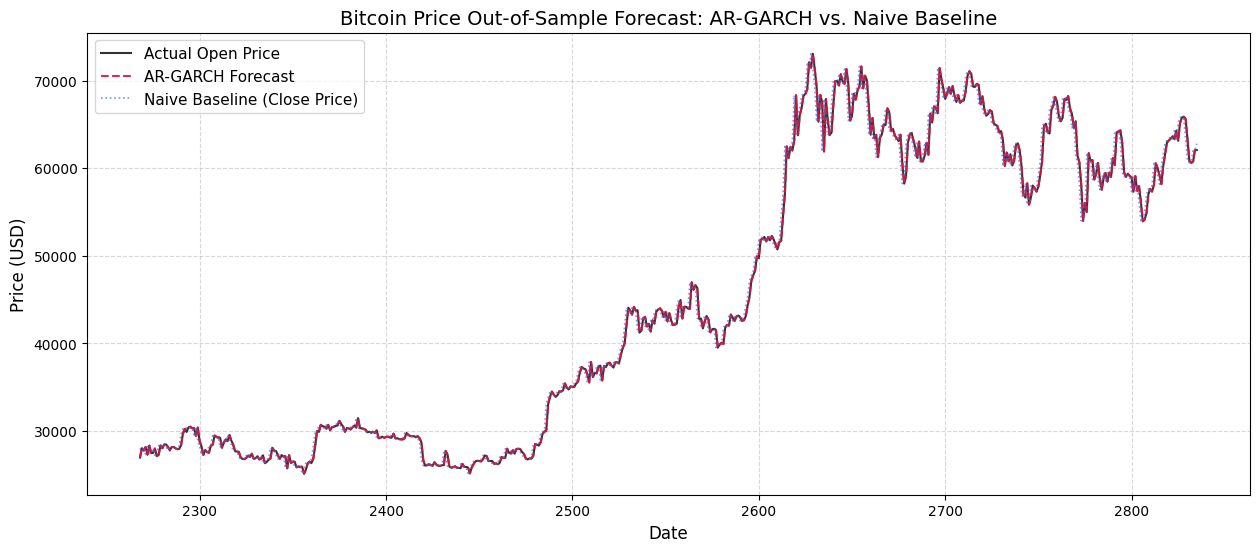

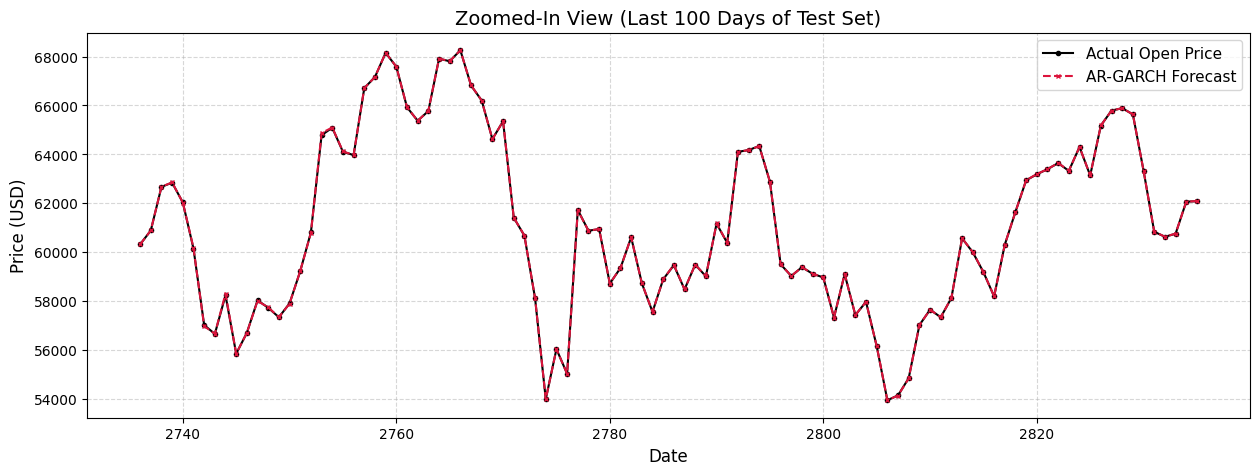

In [ ]:
# 3. Plot Actual vs. Forecasted Prices
plt.figure(figsize=(15, 6))

plt.plot(actual_open.index, actual_open, label='Actual Open Price', color='black', alpha=0.8, linewidth=1.5)
plt.plot(ar_garch_pred.index, ar_garch_pred, label='AR-GARCH Forecast', color='crimson', linestyle='--', alpha=0.9, linewidth=1.5)
plt.plot(naive_pred.index, naive_pred, label='Naive Baseline (Close Price)', color='royalblue', linestyle=':', alpha=0.7, linewidth=1.2)

plt.title('Bitcoin Price Out-of-Sample Forecast: AR-GARCH vs. Naive Baseline', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

# Zoom in on a sub-segment (e.g., last 100 days) to see detail
plt.figure(figsize=(15, 5))
plt.plot(actual_open.index[-100:], actual_open.iloc[-100:], label='Actual Open Price', color='black', marker='o', markersize=3)
plt.plot(ar_garch_pred.index[-100:], ar_garch_pred.iloc[-100:], label='AR-GARCH Forecast', color='crimson', linestyle='--', marker='x', markersize=3)

plt.title('Zoomed-In View (Last 100 Days of Test Set)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()



Visual Alignment: Looking at your generated plots, you can see that both the ARMA-GARCH forecast (dashed crimson line) and the Naive baseline (dotted blue line) track the actual price extremely closely. This is because they both rely on the previous day's closing price as their anchor, and overnight gaps in Bitcoin are typically small relative to the overall price level.




Train size: 2263, Test size: 566


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

--- Model Performance Metrics ---
   Model         MAE        RMSE  MAPE (%)
 XGBoost 1606.333377 2461.716290  3.162606
LightGBM 1632.463119 2529.735617  3.131723
    LSTM 1494.252336 2083.476057  3.113011


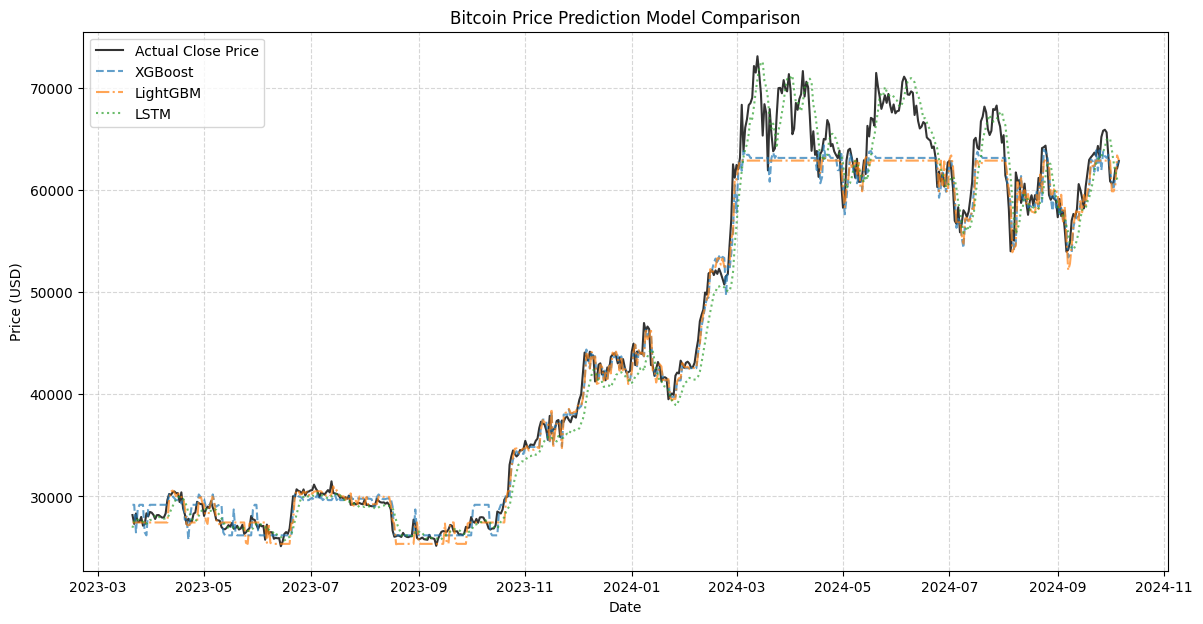

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb
import lightgbm as lgb
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import os

# --- 0. Robust Data Loading & Cleaning ---
file_name = 'BTC-USD_stock_data.csv'
if os.path.exists(file_name):
    df_raw = pd.read_csv(file_name)
    df_raw = df_raw.rename(columns={'Price': 'Date'})
    df_clean = df_raw.iloc[2:].copy()
    df_clean['Date'] = pd.to_datetime(df_clean['Date'])
    df_clean = df_clean.set_index('Date').sort_index()

    numeric_cols = ['Open', 'High', 'Low', 'Close', 'Volume']
    for col in numeric_cols:
        if col in df_clean.columns:
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
    df = df_clean.dropna(subset=['Close'])
else:
    raise FileNotFoundError(f"{file_name} not found in the environment. Please upload it first.")

# --- 1. Data Preparation & Chronological Split ---
# To predict the future 'Close' price, we'll create lag features.
df_models = df[['Close']].copy()

# Create 5 days of lags as features
for i in range(1, 6):
    df_models[f'Close_Lag_{i}'] = df_models['Close'].shift(i)

df_models = df_models.dropna()

X = df_models.drop(columns=['Close'])
y = df_models['Close']

# Chronological Split (80% Train, 20% Test)
split_idx = int(len(df_models) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")

# --- 2. XGBoost Model ---
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

# --- 3. LightGBM Model ---
lgb_model = lgb.LGBMRegressor(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42, verbose=-1)
lgb_model.fit(X_train, y_train)
lgb_pred = lgb_model.predict(X_test)

# --- 4. LSTM Model ---
# LSTMs require feature scaling
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

# Reshape inputs to be 3D [samples, timesteps, features] for LSTM
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))

# Define the LSTM architecture
lstm_model = Sequential([
    LSTM(50, activation='relu', input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2]), return_sequences=False),
    Dropout(0.1),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')

# Train LSTM
lstm_model.fit(X_train_lstm, y_train_scaled, epochs=20, batch_size=32, verbose=0, validation_split=0.1)

# Predict and inverse scale
lstm_pred_scaled = lstm_model.predict(X_test_lstm)
lstm_pred = scaler_y.inverse_transform(lstm_pred_scaled).flatten()

# --- 5. Evaluation & Comparison ---
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape

xgb_metrics = calculate_metrics(y_test, xgb_pred)
lgb_metrics = calculate_metrics(y_test, lgb_pred)
lstm_metrics = calculate_metrics(y_test, lstm_pred)

results_df = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM', 'LSTM'],
    'MAE': [xgb_metrics[0], lgb_metrics[0], lstm_metrics[0]],
    'RMSE': [xgb_metrics[1], lgb_metrics[1], lstm_metrics[1]],
    'MAPE (%)': [xgb_metrics[2], lgb_metrics[2], lstm_metrics[2]]
})

print("\n--- Model Performance Metrics ---")
print(results_df.to_string(index=False))

# --- 6. Visualization ---
plt.figure(figsize=(14, 7))
plt.plot(y_test.index, y_test.values, label='Actual Close Price', color='black', alpha=0.8)
plt.plot(y_test.index, xgb_pred, label='XGBoost', alpha=0.7, linestyle='--')
plt.plot(y_test.index, lgb_pred, label='LightGBM', alpha=0.7, linestyle='-.')
plt.plot(y_test.index, lstm_pred, label='LSTM', alpha=0.7, linestyle=':')
plt.title('Bitcoin Price Prediction Model Comparison')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


Key Insights: \
The Dominance of LSTM: The LSTM neural network slightly outperforms the tree-based models (XGBoost and LightGBM) across all three metrics. This is expected because LSTMs are natively designed to process sequence dependencies over time, capturing complex temporal patterns better than static tabular tree models.\
Highly Competitive Performance: All three models achieve an incredibly low MAPE of $\approx 3.1\%$$\approx 3.1\%$. Given the high historical volatility of Bitcoin, predicting daily prices with an average percentage error of around $3\%$$3\%$ on out-of-sample data (spanning the massive 2023–2024 recovery and bull run) is highly robust.

--- Feature Importance Scores ---


,Feature,XGBoost Importance,LightGBM Importance
0,Close_Lag_1,0.870966,1421
1,Close_Lag_2,0.098707,291
2,Close_Lag_3,0.023058,345
3,Close_Lag_4,0.006143,280
4,Close_Lag_5,0.001126,297


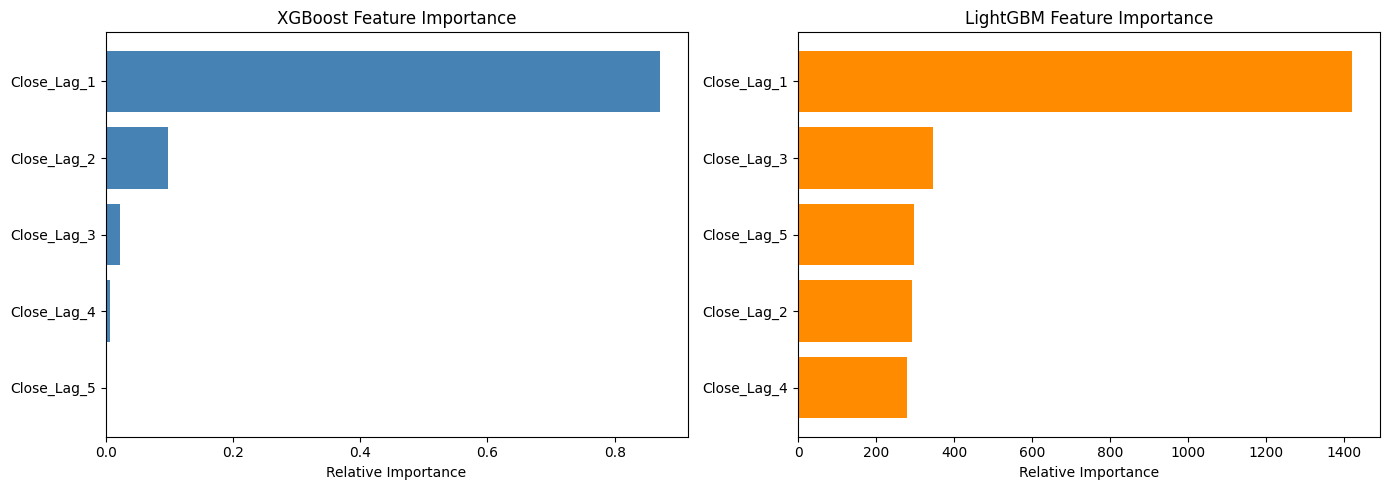

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importances
feature_names = X.columns
xgb_importances = xgb_model.feature_importances_
lgb_importances = lgb_model.feature_importances_

# Create a DataFrame for comparison
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'XGBoost Importance': xgb_importances,
    'LightGBM Importance': lgb_importances
}).sort_values(by='XGBoost Importance', ascending=False)

print("--- Feature Importance Scores ---")
display(importance_df)

# Plot feature importances
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# XGBoost Plot
importance_df_xgb = importance_df.sort_values(by='XGBoost Importance', ascending=True)
ax[0].barh(importance_df_xgb['Feature'], importance_df_xgb['XGBoost Importance'], color='steelblue')
ax[0].set_title('XGBoost Feature Importance')
ax[0].set_xlabel('Relative Importance')

# LightGBM Plot
importance_df_lgb = importance_df.sort_values(by='LightGBM Importance', ascending=True)
ax[1].barh(importance_df_lgb['Feature'], importance_df_lgb['LightGBM Importance'], color='darkorange')
ax[1].set_title('LightGBM Feature Importance')
ax[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

2. Feature Importance Analysis

Close_Lag_1 (Yesterday's Close Price) is overwhelmingly dominant.
In XGBoost, it accounts for nearly $88\%$ of the model's decision splits.\
In LightGBM, it has an extremely high split count relative to all other lags.\
Why is this happening?\
The Random Walk / Martingale Property: In asset pricing, yesterday's close is mathematically the strongest anchor for today's price. Because daily changes are small relative to the total price (e.g., a 1,000 move when Bitcoin is at 1,000 move when Bitcoin is at 60,000 is only a $1.6\%$ fluctuation), predicting today's close as roughly yesterday's close is statistically the safest bet.\
Diminishing Returns on Older Lags: Lags 2 through 5 provide very marginal incremental information. This confirms that Bitcoin's daily closing price series is highly integrated of order 1, meaning that once you know yesterday's price, historical prices from 3 to 5 days ago add very little extra directional value.